# 03 · Rare-word ratio

**Do openings with more rare vocabulary win more often?** Use the published training pairs, Minimal cleaning, randomized A/B assignments, and three discussion-grouped folds from [Notebook 02](word_frequency.ipynb).

Count each listed token occurrence with an English Zipf score **strictly below 3**. That threshold corresponds to fewer than one occurrence per million words in the reference data. Divide by the number of listed token occurrences. Unlisted words stay out of the numerator and denominator and are audited separately. This ratio measures the low-frequency tail of vocabulary. The previous notebook's mean Zipf summarizes the entire listed vocabulary. [wordfreq documentation](https://github.com/rspeer/wordfreq#usage)

The [standalone script](analyze_rare_word_ratio.py) saves timestamped runs. Install `wordfreq==3.1.1` in the active kernel to regenerate.

In [1]:
import json
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/linguistic-features/rare-word-ratio"
SCRIPT = REPO / "project/notebooks/linguistic-features/lexical-complexity/analyze_rare_word_ratio.py"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    subprocess.run([sys.executable, str(SCRIPT)], check=True)
    runs = sorted(RUNS.glob("*/results.json"))
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
report = json.loads(report_path.read_text())
pairs = pd.read_parquet(report_path.parent / "paired_scores.parquet")
openings = pd.read_parquet(report_path.parent / "opening_scores.parquet")
print(f"{len(pairs):,} complete pairs · {len(openings):,} unique openings · {report['discussions']:,} discussions")
print(f"{report['listed_token_share']:.2%} of token occurrences received a reference score.")
print(f"{report['shared_pairs'] - len(pairs):,} shared pairs excluded for missing rare-word ratios.")
print(f"Rare among listed token occurrences: {report['rare_share_among_listed_tokens']:.2%}")

3,451 complete pairs · 6,581 unique openings · 2,507 discussions
99.87% of token occurrences received a reference score.
0 shared pairs excluded for missing rare-word ratios.
Rare among listed token occurrences: 1.42%


## Distribution and examples

Summarize each distinct opening once. Show openings at the top of the rare-word distribution and inspect some of the counted words. Rare terms may include proper names, specialized vocabulary, spelling variants, and informal language. A topical term can be unfamiliar in general English and familiar within that discussion.

In [2]:
feature = "rare_word_ratio"
display(openings[[feature, "tokens", "rare_tokens", "unlisted_share"]].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).round(4))
print(f"Openings with zero listed rare words: {int(openings['rare_tokens'].eq(0).sum()):,}")
display(openings.nlargest(6, feature)[[
    feature, "tokens", "rare_tokens", "unlisted_share", "rare_examples", "opening_preview",
]].round(4))

,rare_word_ratio,tokens,rare_tokens,unlisted_share
count,6581.0000,6581.0000,6581.0000,6581.0000
mean,0.0138,234.7394,3.3352,0.0013
std,0.0135,193.3809,4.4014,0.0042
min,0.0000,40.0000,0.0000,0.0000
1%,0.0000,51.0000,0.0000,0.0000
25%,0.0040,107.0000,1.0000,0.0000
50%,0.0108,176.0000,2.0000,0.0000
75%,0.0197,296.0000,4.0000,0.0000
99%,0.0588,987.4000,21.0000,0.0189
max,0.1186,1724.0000,65.0000,0.1261


Openings with zero listed rare words: 1,447


,rare_word_ratio,tokens,rare_tokens,unlisted_share,rare_examples,opening_preview
comment_id,,,,,,
t1_cabbfp2,0.1186,222,23,0.1261,"redditors, outerspace, macklemore, k'naan, sucka, olu, papoose, hopsin","Here is a list of video links collected from comments that redditors have made in response to this submission: |Source Comment|Score|Video Link| |:-------|:-------|:-------| |melonzz|10|Jedi Mind Tricks - ""I Against I"" feat. Planetary of Ou"
t1_cdhpzkr,0.1111,55,6,0.0182,"heteronormative, subsets","Heteronormative and nonheteronormative are subsets of typical and atypical, respectively. Something that is heteronormative is always typical, but not everything that is typical is heteronormative. Wearing shoes is typical, but it is not he"
t1_clstk0s,0.0943,53,5,0.0000,licorice,"What about this obvious exception: licorice. People tend to have polarized views on licorice: love or hate. If the mixed bad contain licorice, than random distribution will quickly lead to inefficient distribution of candy: Those who love l"
t1_cgybkki,0.0915,328,30,0.0000,"dennett's, qualia, materialist, incorrigible, dennett, experiential, dualists, debunks","Dennett's book ""Sweet Dreams"" is almost completely devoted to responding to Chalmers directly. He opposes the concept of qualia, not because we don't have first-person experience, but because qualia as typically defined is incoherent. A coh"
t1_cap6tx5,0.0909,88,8,0.0000,"introverted, extroverted, introversion, extroversion, extroverts","Being shy isn't the same as being introverted. People who are extroverted can still have social anxiety disorder or appear as if they were introverted. I'm introverted, but I'm very self confident and don't have a negative self image. Being"
t1_c9t4zgp,0.0893,58,5,0.0345,"desertification, sequestration, grasslands, halving, unecessary","Holisitic management can fight desertification and aid in carbon sequestration in grasslands. So it's possible to make beef less resource intensive, and even reverse climate change. From your link on water: Another of your links is even tit"


## Paired association and standalone prediction

Report the share of unequal-score pairs in which the winner had the higher rare-word ratio. Ties are separate. The intervals resample whole OP discussions. The close-length check uses shared opening word counts and keeps pairs within 50 words.

The classifier predicts whether A wins from `rare_word_ratio_A − rare_word_ratio_B` on the shared validation folds. Scaling is fitted inside each fold. ROC-AUC is primary, and average precision is compared with the A-wins prevalence. Spearman correlation with opening length uses distinct analyzed openings. All results are associations within published pairs.

In [3]:
metrics = pd.DataFrame({
    "All pairs": report["winner_higher"], "Within 50 words": report["within_50_words"],
}).T
metrics["winner_higher_pct"] = 100 * metrics["winner_higher_rate"].astype(float)
metrics["CI lower_pct"] = metrics["ci_95"].map(lambda interval: 100 * interval[0])
metrics["CI upper_pct"] = metrics["ci_95"].map(lambda interval: 100 * interval[1])
display(metrics[[
    "pairs", "winner_higher", "winner_lower", "ties",
    "winner_higher_pct", "CI lower_pct", "CI upper_pct",
]].infer_objects().round(3))
display(pd.Series({
    "ROC-AUC": report["prediction"]["roc_auc"],
    "Average precision": report["prediction"]["average_precision"],
    "A-wins prevalence": report["prediction"]["a_win_prevalence"],
    "Spearman vs word count": report["spearman_with_word_count"],
}, name="value").round(4).to_frame())

,pairs,winner_higher,winner_lower,ties,winner_higher_pct,CI lower_pct,CI upper_pct
All pairs,3451,1843,1355,253,57.630,55.777,59.371
Within 50 words,1144,547,443,154,55.253,51.934,58.418


,value
ROC-AUC,0.5858
Average precision,0.5561
A-wins prevalence,0.4967
Spearman vs word count,0.1322


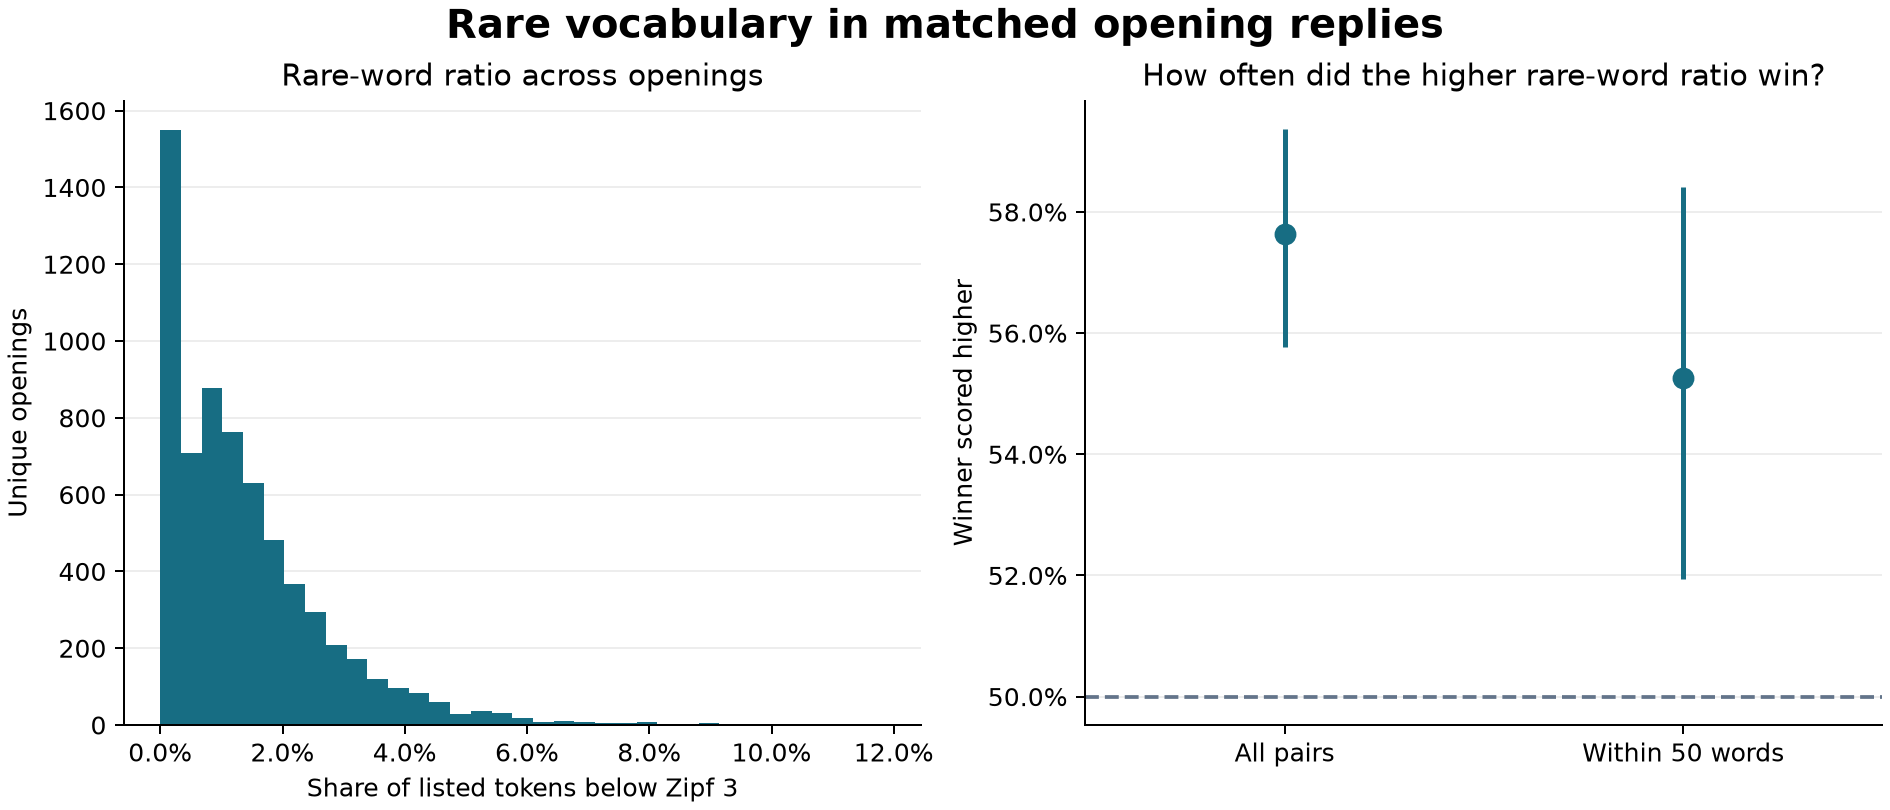

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, (distribution, paired_plot) = plt.subplots(1, 2, figsize=(10.5, 4.5), layout="constrained")
fig.suptitle("Rare vocabulary in matched opening replies", weight="bold", fontsize=16)
distribution.hist(openings[feature], bins=35, color="#176d83")
distribution.set(title="Rare-word ratio across openings", xlabel="Share of listed tokens below Zipf 3",
                 ylabel="Unique openings")
distribution.xaxis.set_major_formatter(PercentFormatter(1))
x = np.arange(len(metrics))
paired_plot.axhline(50, linestyle="--", color="#63748a")
paired_plot.vlines(x, metrics["CI lower_pct"], metrics["CI upper_pct"], color="#176d83", lw=2)
paired_plot.scatter(x, metrics["winner_higher_pct"], color="#176d83", s=60, zorder=3)
paired_plot.set_xticks(x, metrics.index.tolist())
paired_plot.set(title="How often did the higher rare-word ratio win?",
                ylabel="Winner scored higher", xlim=(-0.5, len(x) - 0.5))
paired_plot.yaxis.set_major_formatter(PercentFormatter(100))
for ax in (distribution, paired_plot):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)
fig.savefig(report_path.parent / "rare_word_ratio_comparison.png", dpi=180, facecolor="white")
plt.show()

## Sensitivity to the Zipf cutoff and token filter

Recompute the rare-word ratio at fixed cutoffs of **Zipf < 2**, **Zipf < 3**, and **Zipf < 4**. For each cutoff, compare all words with content words only. Content words use the same English POS tags (nouns, verbs, adjectives, and adverbs) as [the mean Zipf sensitivity analysis](word_frequency.ipynb). Both filters count repeated occurrences and divide by the number of listed occurrences retained by that filter.

Use the same complete training pairs, A/B assignments, and OP-discussion folds for every row. Add the content-word mean Zipf benchmark on those same pairs and tokens to compare a vocabulary average with a low-frequency share. The winner percentages and discussion-bootstrap intervals use pairs with unequal scores. Out-of-fold ROC-AUC and average precision use all common pairs, including ties.

All words with Zipf < 3 remains the primary definition. Treat each other cutoff and filter as a sensitivity check and report every row without selecting a cutoff using these folds.

The [standalone sensitivity script](analyze_rare_word_ratio_sensitivity.py) saves timestamped runs. To regenerate, install `nltk==3.10.4` in addition to the wordfreq dependency and run `python -m nltk.downloader averaged_perceptron_tagger_eng` in the active environment.

In [5]:
SENSITIVITY_RUNS = RUNS.parent / "rare-word-ratio-sensitivity"
SENSITIVITY_SCRIPT = SCRIPT.with_name("analyze_rare_word_ratio_sensitivity.py")
SENSITIVITY_RUN_ID = None
sensitivity_runs = sorted(SENSITIVITY_RUNS.glob("*/results.json"))
if SENSITIVITY_RUN_ID is None and not sensitivity_runs:
    subprocess.run([sys.executable, str(SENSITIVITY_SCRIPT)], check=True)
    sensitivity_runs = sorted(SENSITIVITY_RUNS.glob("*/results.json"))
sensitivity_path = (
    SENSITIVITY_RUNS / SENSITIVITY_RUN_ID / "results.json"
    if SENSITIVITY_RUN_ID else sensitivity_runs[-1]
)
sensitivity = json.loads(sensitivity_path.read_text())

filter_labels = {"all_words": "All words", "content_words": "Content words"}
rows = []
for metric in sensitivity["metrics"]:
    cutoff = metric["zipf_cutoff_exclusive"]
    measure = f"Zipf < {cutoff}" if cutoff is not None else "Mean Zipf"
    if metric["feature"] == sensitivity["primary_feature"]:
        measure += " (primary)"
    low, high = metric["ci_95"]
    higher = metric["winner_higher_rate"]
    rare_share = metric["rare_share_of_listed_tokens"]
    rows.append({
        "Token filter": filter_labels[metric["token_filter"]],
        "Measure": measure,
        "Rare tokens (%)": f"{rare_share:.2%}" if rare_share is not None else "—",
        "Tied pairs": metric["ties"],
        "Higher score won": f"{higher:.1%}" if higher is not None else "—",
        "95% CI": f"{low:.1%}–{high:.1%}" if low is not None else "—",
        "ROC-AUC": metric["roc_auc"],
        "Average precision": metric["average_precision"],
    })
sensitivity_table = pd.DataFrame(rows).set_index(["Token filter", "Measure"])
print(
    f"Common training sample: {sensitivity['complete_pairs']:,} of "
    f"{sensitivity['shared_pairs']:,} pairs across {sensitivity['discussions']:,} discussions."
)
display(sensitivity_table.round(4))

Common training sample: 3,451 of 3,451 pairs across 2,507 discussions.


Rare tokens (%)  Tied pairs Higher score won       95% CI  ROC-AUC  Average precision
Token filter  Measure                                                                                                 
All words     Zipf < 2                     0.23%        1833            58.8%  56.4%–61.3%   0.5617             0.5286
              Zipf < 3 (primary)           1.42%         253            57.6%  55.8%–59.4%   0.5858             0.5561
              Zipf < 4                     6.76%           6            56.6%  54.9%–58.2%   0.5815             0.5613
Content words Zipf < 2                     0.39%        1842            59.0%  56.5%–61.3%   0.5617             0.5285
              Zipf < 3                     2.43%         258            57.7%  56.0%–59.4%   0.5876             0.5586
              Zipf < 4                    11.53%           9            56.8%  55.1%–58.5%   0.5872             0.5657
              Mean Zipf                        —           1            41.7%  39.9%–43.4%   0.6154             0.6005